# 9. Generalizacja algorytmów na nowe domeny

Notebook ponownie oblicza wyniki pięciu algorytmów V4 dla wariantów `full` i `selected`. Porównuje stały test wewnętrzny (21 000 rekordów) z poprawionym zewnętrznym cache `recheck_v4_domain_fix` (37 790 rekordów). Nakładanie domen rejestrowalnych jest audytowane względem aktualnego testu V4.

Przedziały ufności 95% powstają przez bootstrap warstwowy względem klasy: 1000 replik, seed 42. Nie występuje ponowne trenowanie. Negatywny quality gate pozostaje pełnoprawnym wynikiem naukowym.

In [1]:
import importlib
import os
import sys
from pathlib import Path


def locate_backend_root():
    candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    for candidate in candidates:
        nested_backend = candidate / 'backend'
        if (candidate / 'config').is_dir() and (candidate / 'notebooks').is_dir():
            return candidate
        if (nested_backend / 'config').is_dir() and (nested_backend / 'notebooks').is_dir():
            return nested_backend
    raise FileNotFoundError('Nie znaleziono katalogu backend')


backend_root = locate_backend_root()
notebooks_dir = backend_root / 'notebooks' / 'url_corpus'
os.chdir(notebooks_dir)
sys.path.insert(0, str(backend_root))
os.environ.setdefault('MPLCONFIGDIR', '/tmp/phishing-detector-matplotlib')
if 'utils.notebook_plot_style' in sys.modules:
    importlib.reload(sys.modules['utils.notebook_plot_style'])
print(f'Backend: {backend_root}')


Backend: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/backend


In [2]:
import json

import pandas as pd
import tldextract

from config.feature_names_config import FeatureConfig
from config.feature_policy import FEATURE_POLICY_VERSION
from config.project_paths import RESULTS_ROOT
from scripts.recheck_url_corpus_models import load_payload, predict
from utils.benchmark_plots import plot_generalization_results
from utils.research_benchmark import (
    binary_metrics,
    prediction_checksum,
    quality_gate,
    stratified_bootstrap,
    validate_staged_payload,
)

RANDOM_STATE = 42
BOOTSTRAP_REPETITIONS = 1000
ALGORITHMS = ('logistic_regression', 'random_forest', 'xgboost', 'svm', 'mlp')
MODES = ('full', 'selected')
MODEL_LABELS = {
    'logistic_regression': 'Regresja Logistyczna',
    'random_forest': 'Random Forest',
    'xgboost': 'XGBoost',
    'svm': 'SVM',
    'mlp': 'MLP',
}
MODEL_ROOT = backend_root / 'models' / 'staged_url_corpus_v4'
INTERNAL_ROOT = backend_root / 'data' / 'url_corpus' / 'quality_v4_repaired_features'
EXTERNAL_ROOT = RESULTS_ROOT / 'url_corpus' / 'recheck_v4_domain_fix' / 'external_features'
OUTPUT_DIR = RESULTS_ROOT / 'url_corpus' / 'external_generalization'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f'Wyniki: {OUTPUT_DIR}')


Wyniki: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/external_generalization


## Niezależność domen

Kontrola wykorzystuje domenę rejestrowalną, a nie pełny URL. Cache był filtrowany względem historycznego `quality_large_splits`; notebook sprawdza, czy deklarowana niezależność zachowała się względem aktualnego `quality_v4_repaired`. Wykryte przecięcie jest raportowane i nie jest ukrywane.

In [3]:
domain_extractor = tldextract.TLDExtract(cache_dir=None, suffix_list_urls=())


def registered_domain(url):
    extracted = domain_extractor(url)
    return f'{extracted.domain}.{extracted.suffix}' if extracted.suffix else extracted.domain


internal_urls = pd.read_csv(INTERNAL_ROOT / 'dataset_full_test.csv', usecols=['url'])['url']
external_urls = pd.read_csv(EXTERNAL_ROOT / 'external_full.csv', usecols=['url'])['url']
internal_domains = {registered_domain(url) for url in internal_urls}
external_domains = {registered_domain(url) for url in external_urls}
overlap = sorted(internal_domains & external_domains)
domain_audit = {
    'internal_rows': len(internal_urls),
    'external_rows': len(external_urls),
    'internal_domains': len(internal_domains),
    'external_domains': len(external_domains),
    'overlap_domains': len(overlap),
    'overlap_examples': overlap[:20],
}
assert domain_audit['internal_rows'] == 21000
assert domain_audit['external_rows'] == 37790
(OUTPUT_DIR / 'domain_overlap_audit.json').write_text(
    json.dumps(domain_audit, ensure_ascii=False, indent=2) + '\n',
    encoding='utf-8',
)
domain_audit


{'internal_rows': 21000,
 'external_rows': 37790,
 'internal_domains': 12591,
 'external_domains': 28436,
 'overlap_domains': 194,
 'overlap_examples': ['1377x.to',
  'abplive.com',
  'addictinggames.com',
  'afsp.org',
  'aftenposten.no',
  'alfredstate.edu',
  'alternativeto.net',
  'animanch.com',
  'ansi.org',
  'anydesk.com',
  'anyflip.com',
  'apollohospitals.com',
  'appspace.com',
  'ask.com',
  'aspirus.org',
  'aspose.app',
  'auctria.com',
  'bbiq.jp',
  'bcg.com',
  'bdsmovement.net']}

## Ponowne obliczenie predykcji i metryk

Każdy artefakt przechodzi walidację schematu, skalera, polityki cech i progu. Metryki są liczone z nowych predykcji na obu zbiorach. Checksumy zapisują etykiety i prawdopodobieństwa, umożliwiając wykrycie późniejszej zmiany wyników.

In [4]:
metric_rows = []
interval_rows = []
checksum_rows = []
gate_rows = []
for mode in MODES:
    frames = {
        'internal': pd.read_csv(INTERNAL_ROOT / f'dataset_{mode}_test.csv'),
        'external': pd.read_csv(EXTERNAL_ROOT / f'external_{mode}.csv'),
    }
    expected_columns = FeatureConfig.get_feature_names(mode)
    for algorithm in ALGORITHMS:
        payload = load_payload(MODEL_ROOT, algorithm, mode)
        validate_staged_payload(
            payload, expected_columns, algorithm, mode, FEATURE_POLICY_VERSION
        )
        threshold = float(payload['decision_threshold'])
        for dataset, frame in frames.items():
            labels = frame['phishing'].to_numpy(dtype=int)
            probabilities = predict(payload, frame)
            metrics = binary_metrics(labels, probabilities, threshold)
            metric_rows.append({
                'algorithm': algorithm,
                'mode': mode,
                'dataset': dataset,
                'rows': len(frame),
                'threshold': threshold,
                **metrics,
            })
            intervals = stratified_bootstrap(
                labels, probabilities, threshold, BOOTSTRAP_REPETITIONS, RANDOM_STATE
            )
            interval_rows.extend({
                'algorithm': algorithm,
                'mode': mode,
                'dataset': dataset,
                'metric': metric,
                'lower_95': bounds[0],
                'upper_95': bounds[1],
                'repetitions': BOOTSTRAP_REPETITIONS,
                'seed': RANDOM_STATE,
            } for metric, bounds in intervals.items())
            checksum_rows.append({
                'algorithm': algorithm,
                'mode': mode,
                'dataset': dataset,
                'rows': len(frame),
                'prediction_sha256': prediction_checksum(labels, probabilities),
            })
            if dataset == 'external':
                gate_rows.append({'algorithm': algorithm, 'mode': mode, **quality_gate(metrics)})
metrics_frame = pd.DataFrame(metric_rows)
intervals_frame = pd.DataFrame(interval_rows)
checksums_frame = pd.DataFrame(checksum_rows)
gates_frame = pd.DataFrame(gate_rows)
metrics_frame.to_csv(OUTPUT_DIR / 'generalization_metrics.csv', index=False)
intervals_frame.to_csv(OUTPUT_DIR / 'bootstrap_intervals_95.csv', index=False)
checksums_frame.to_csv(OUTPUT_DIR / 'prediction_checksums.csv', index=False)
gates_frame.to_csv(OUTPUT_DIR / 'quality_gate_by_algorithm.csv', index=False)
display(metrics_frame)
display(intervals_frame)


,algorithm,mode,dataset,rows,threshold,accuracy,precision,recall,f1,roc_auc,false_positive_rate,specificity
0,logistic_regression,full,internal,21000,0.577585,0.861000,0.899631,0.812667,0.853940,0.905651,0.090667,0.909333
1,logistic_regression,full,external,37790,0.577585,0.829532,0.783474,0.910770,0.842340,0.930739,0.251707,0.748293
2,random_forest,full,internal,21000,0.431528,0.911048,0.946976,0.870857,0.907323,0.978688,0.048762,0.951238
3,random_forest,full,external,37790,0.431528,0.850701,0.793507,0.948134,0.863956,0.953855,0.246732,0.753268
4,xgboost,full,internal,21000,0.443208,0.929000,0.960253,0.895048,0.926505,0.984629,0.037048,0.962952
5,xgboost,full,external,37790,0.443208,0.867849,0.810276,0.960625,0.879068,0.970651,0.224927,0.775073
6,svm,full,internal,21000,0.261618,0.920524,0.924526,0.915810,0.920147,0.966256,0.074762,0.925238
7,svm,full,external,37790,0.261618,0.813019,0.748686,0.942366,0.834435,0.944242,0.316327,0.683673
8,mlp,full,internal,21000,0.446199,0.931095,0.934363,0.927333,0.930835,0.978794,0.065143,0.934857
9,mlp,full,external,37790,0.446199,0.825060,0.762816,0.943477,0.843582,0.950569,0.293358,0.706642


,algorithm,mode,dataset,metric,lower_95,upper_95,repetitions,seed
0,logistic_regression,full,internal,accuracy,0.856333,0.865714,1000,42
1,logistic_regression,full,internal,precision,0.894107,0.905035,1000,42
2,logistic_regression,full,internal,recall,0.805238,0.820290,1000,42
3,logistic_regression,full,internal,f1,0.848797,0.859083,1000,42
4,logistic_regression,full,internal,roc_auc,0.901322,0.909984,1000,42
...,...,...,...,...,...,...,...,...
135,mlp,selected,external,recall,0.941994,0.948452,1000,42
136,mlp,selected,external,f1,0.859770,0.865540,1000,42
137,mlp,selected,external,roc_auc,0.953937,0.958243,1000,42
138,mlp,selected,external,false_positive_rate,0.240327,0.252502,1000,42


In [5]:
metric_names = (
    'accuracy',
    'precision',
    'recall',
    'f1',
    'roc_auc',
    'false_positive_rate',
    'specificity',
)
difference_rows = []
for (algorithm, mode), group in metrics_frame.groupby(['algorithm', 'mode']):
    indexed = group.set_index('dataset')
    difference_rows.extend({
        'algorithm': algorithm,
        'mode': mode,
        'metric': metric,
        'internal_minus_external': indexed.loc['internal', metric] - indexed.loc['external', metric],
        'internal': indexed.loc['internal', metric],
        'external': indexed.loc['external', metric],
    } for metric in metric_names)
differences_frame = pd.DataFrame(difference_rows)
differences_frame.to_csv(OUTPUT_DIR / 'internal_external_differences.csv', index=False)
gate_report = {
    'criteria': {'roc_auc_minimum': 0.80, 'specificity_minimum': 0.80},
    'all_external_quality_gates_passed': bool(gates_frame['passed'].all()),
    'results': gates_frame.to_dict(orient='records'),
    'interpretation': 'Wynik negatywny nie jest ukrywany i blokuje promocję artefaktów V4.',
}
(OUTPUT_DIR / 'quality_gate.json').write_text(
    json.dumps(gate_report, ensure_ascii=False, indent=2) + '\n',
    encoding='utf-8',
)
display(differences_frame)
gates_frame


,algorithm,mode,metric,internal_minus_external,internal,external
0,logistic_regression,full,accuracy,0.031468,0.861000,0.829532
1,logistic_regression,full,precision,0.116157,0.899631,0.783474
2,logistic_regression,full,recall,-0.098103,0.812667,0.910770
3,logistic_regression,full,f1,0.011601,0.853940,0.842340
4,logistic_regression,full,roc_auc,-0.025088,0.905651,0.930739
...,...,...,...,...,...,...
65,xgboost,selected,recall,-0.088604,0.875619,0.964223
66,xgboost,selected,f1,0.045497,0.912284,0.866787
67,xgboost,selected,roc_auc,0.012247,0.982973,0.970726
68,xgboost,selected,false_positive_rate,-0.216598,0.044000,0.260598


,algorithm,mode,roc_auc_minimum,specificity_minimum,roc_auc_passed,specificity_passed,passed
0,logistic_regression,full,0.8,0.8,True,False,False
1,random_forest,full,0.8,0.8,True,False,False
2,xgboost,full,0.8,0.8,True,False,False
3,svm,full,0.8,0.8,True,False,False
4,mlp,full,0.8,0.8,True,False,False
5,logistic_regression,selected,0.8,0.8,True,False,False
6,random_forest,selected,0.8,0.8,True,False,False
7,xgboost,selected,0.8,0.8,True,False,False
8,svm,selected,0.8,0.8,True,False,False
9,mlp,selected,0.8,0.8,True,False,False


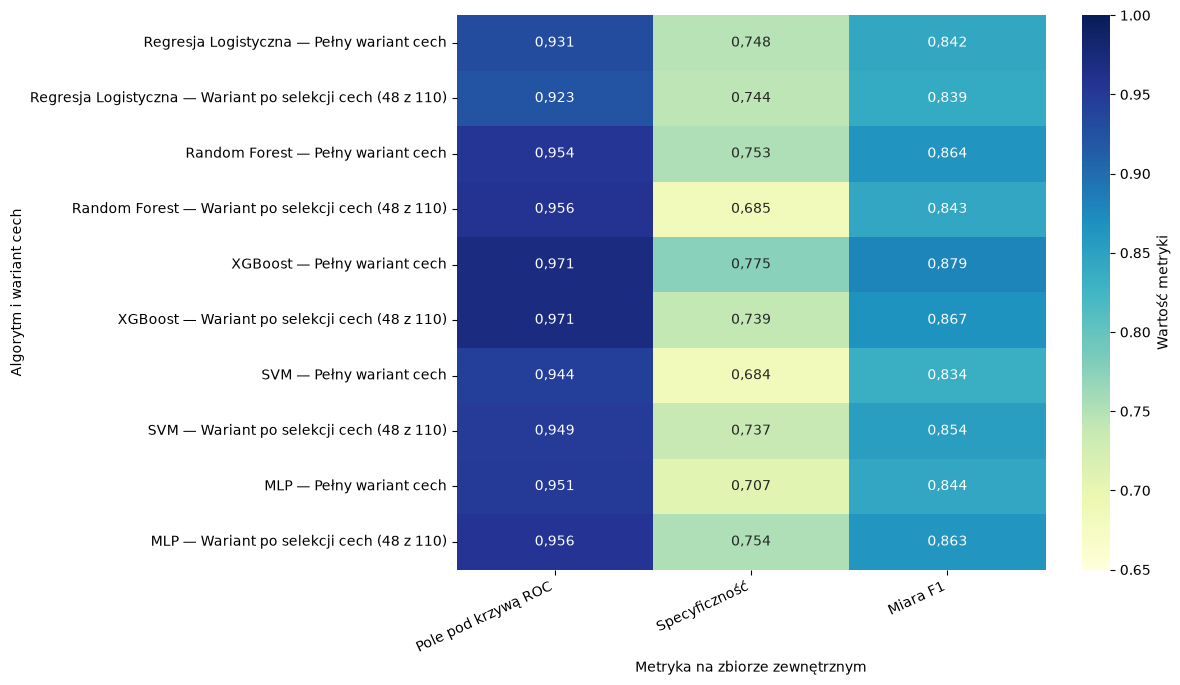

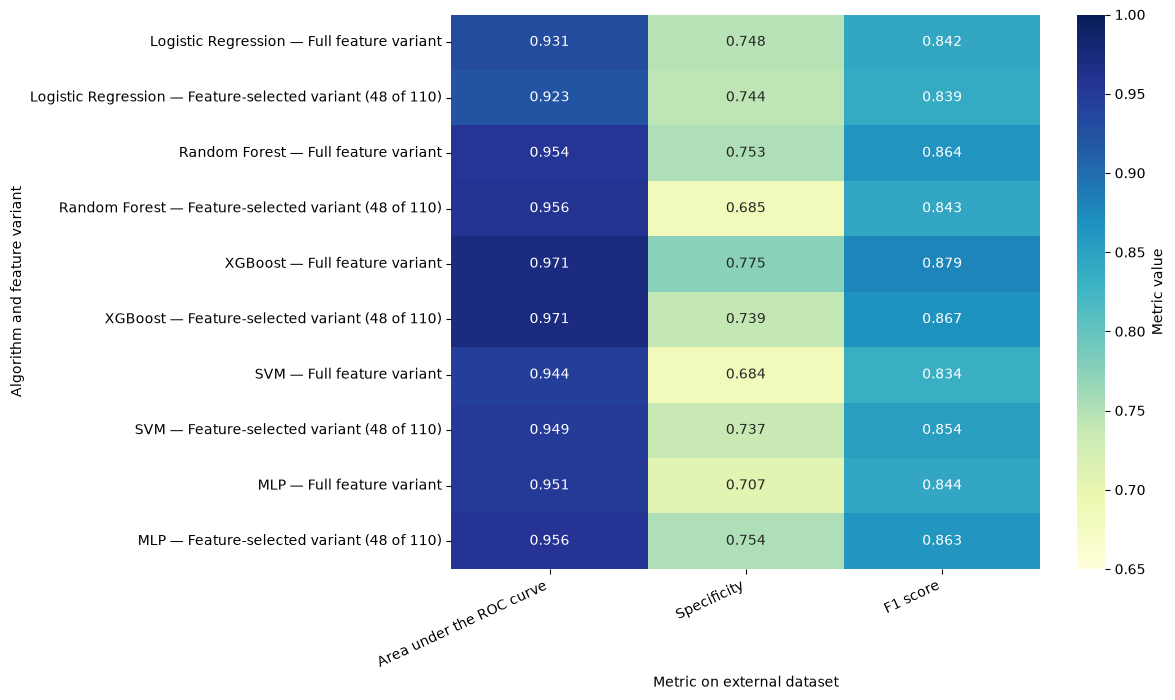

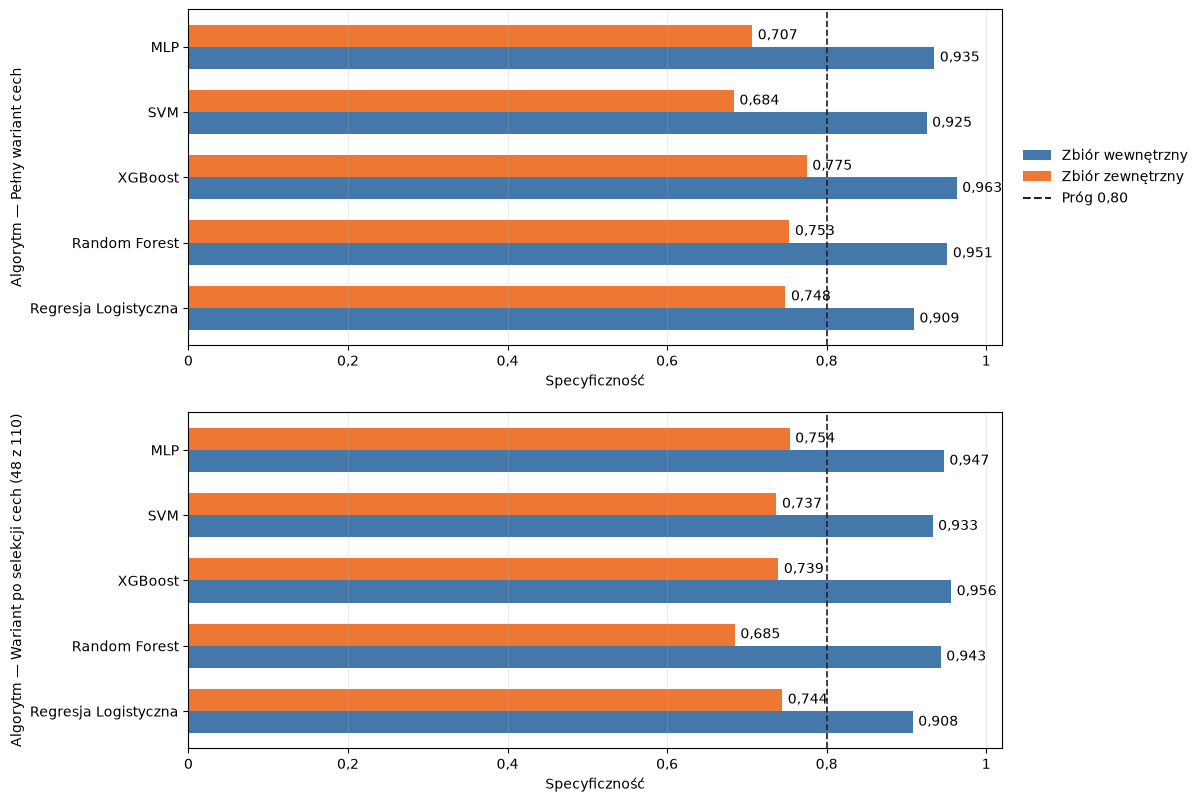

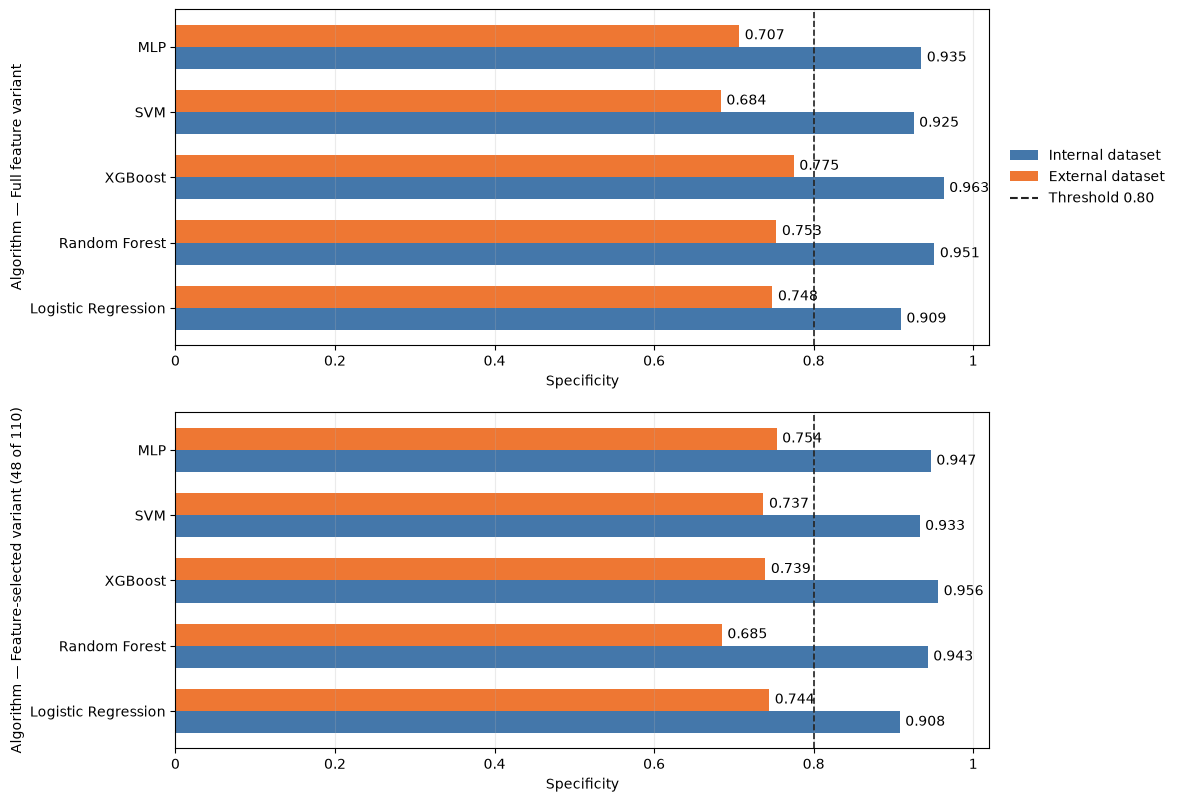

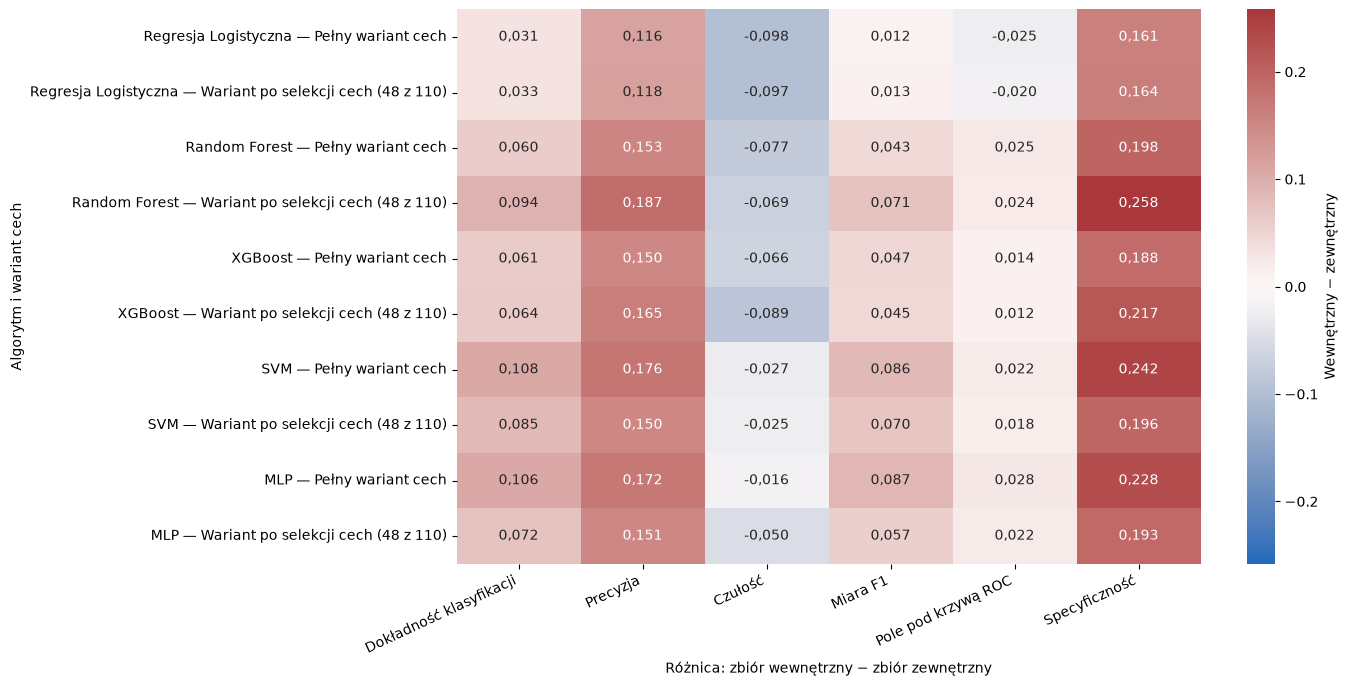

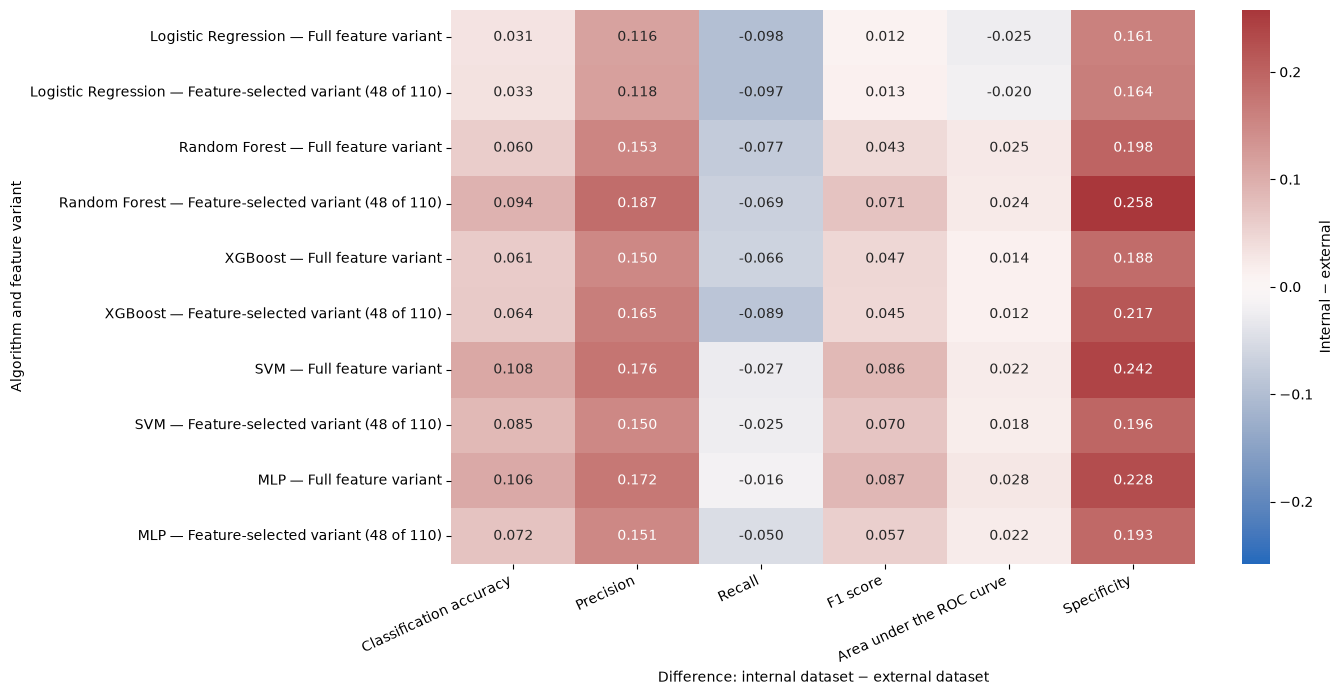

In [1]:
plot_generalization_results(metrics_frame, differences_frame, OUTPUT_DIR, MODEL_LABELS)


## Interpretacja i ograniczenia

- test wewnętrzny mierzy działanie na danych z tego samego procesu przygotowania, a test zewnętrzny — przenoszenie decyzji na nowe domeny;
- dodatnia różnica `internal_minus_external` oznacza spadek danej metryki na zbiorze zewnętrznym, z wyjątkiem FPR, gdzie kierunek należy interpretować odwrotnie;
- bootstrap opisuje niepewność próbkowania rekordów przy stałym algorytmie, progu i zbiorze cech; nie obejmuje niepewności ponownego uczenia;
- audyt domen rozstrzyga, czy cache można nazywać domenowo rozłącznym względem aktualnego V4; wykryte przecięcie ogranicza siłę wniosku o generalizacji;
- quality gate wymaga jednocześnie ROC AUC ≥ 0,80 i specyficzności ≥ 0,80;
- wynik gate nie jest podstawą do zmiany domyślnego algorytmu ani promocji V4.

In [7]:
failed = gates_frame[~gates_frame['passed']]
print(f"Quality gate spełniony dla {int(gates_frame['passed'].sum())}/{len(gates_frame)} wariantów.")
print(f"Przecięcie domen rejestrowalnych: {domain_audit['overlap_domains']}.")
if len(failed):
    labels_failed = [
        f"{MODEL_LABELS[row.algorithm]} ({row.mode})"
        for row in failed.itertuples()
    ]
    print('Niespełnione warianty: ' + ', '.join(labels_failed))
print('Brak promocji artefaktów pozostaje uzasadniony, jeśli choć jeden wymagany gate nie przechodzi.')


Quality gate spełniony dla 0/10 wariantów.
Przecięcie domen rejestrowalnych: 194.
Niespełnione warianty: Regresja Logistyczna (full), Random Forest (full), XGBoost (full), SVM (full), MLP (full), Regresja Logistyczna (selected), Random Forest (selected), XGBoost (selected), SVM (selected), MLP (selected)
Brak promocji artefaktów pozostaje uzasadniony, jeśli choć jeden wymagany gate nie przechodzi.
